# v6b analysis B (GPU 1): crosscoder, force-on (100 neurons, every language), damage + relearn (every language, 3 models)
Phase-45 models: continual, Hindi only, mixed. **Run All.** About 1.5 hours. Then save (Ctrl+S); notebook A's last cell pushes everything.

In [1]:
import os, sys, glob, json, time, subprocess
os.environ["HF_HUB_DISABLE_XET"] = "1"
GPU = "1"
REPO = "/workspace/shreshth"; os.chdir(REPO); sys.path.insert(0, REPO)
from IPython.display import Image, display
from huggingface_hub import HfApi, hf_hub_download
for attempt in range(5):
    try:
        api = HfApi(); HF_REPO = api.whoami()["name"] + "/cml-lang-self-checkpoints"; FILES = api.list_repo_files(HF_REPO); break
    except Exception as e:
        print("HF retry", attempt, type(e).__name__); time.sleep(10)

def get(run, phases):
    for ph in phases:
        if glob.glob(f"runs/{run}/ckpt/p{ph:03d}_*.pt"):
            continue
        name = [f for f in FILES if f.startswith(f"{run}/ckpt/p{ph:03d}_")]
        if name:
            hf_hub_download(HF_REPO, name[0], local_dir="runs")
        else:
            print("missing (not here, not on HF):", run, ph)

def run(*cmd):
    p = subprocess.Popen([sys.executable, "-u", *cmd], stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    for line in p.stdout:
        print(line, end="")
    p.wait(); print("exit code", p.returncode)

MIXED, REDO = "v6b_mixed_s0", "v6b_cont_redo_from60"
for r in [MIXED, REDO]:
    print(r, "checkpoints:", len(glob.glob(f"runs/{r}/ckpt/p*.pt")))

v6b_mixed_s0 checkpoints: 61
v6b_cont_redo_from60 checkpoints: 31


In [2]:
# wait until notebook A has downloaded the checkpoints (it starts the downloads); rerun this cell if something is missing
need = json.loads(subprocess.check_output([sys.executable, "analysis_v6c.py", "--list"]))
for r, phs in need.items():
    get(r, phs)
print("ok")

ok


In [3]:
run("analysis_v6c.py", "--gpu", GPU, "--parts", "crosscoder", "steer", "relearn", "--tag", "B")

analysis_v6c | cont v4b_continual_s0 | hi v4b_only_hi_s0 | mixed v6b_mixed_s0 | redo v6b_cont_redo_from60 | push v6_hi_push0.6_from30 | phase 45 | tau 0.2 | parts ['crosscoder', 'steer', 'relearn']

=== CROSSCODER: which decoder features a switch replaces, do they come back, are self features kept more? ===
  continual 44 (zh) vs 45 (ar): switch           kept  61%  lost   9%  new   7% | self features kept  53% vs task features kept  62% (291 vs 7901 features) | unexplained 0.38/0.34 [4.9 min]
  continual 44 (zh) vs 46 (hi): two switches     kept  68%  lost   9%  new   6% | self features kept  54% vs task features kept  68% (289 vs 7903 features) | unexplained 0.38/0.34 [4.9 min]
  Hindi only 44 vs 45                            kept 100%  lost   0%  new   0% | self features kept 100% vs task features kept 100% (4814 vs 3378 features) | unexplained 0.19/0.19 [4.9 min]
  mixed 44 vs 45                                 kept 100%  lost   0%  new   0% | self features kept 100% vs task featur

analysis_v6c | cont v4b_continual_s0 | hi v4b_only_hi_s0 | mixed v6b_mixed_s0 | redo v6b_cont_redo_from60 | push v6_hi_push0.6_from30 | phase 45 | tau 0.2 | parts ['crosscoder', 'steer', 'relearn']

=== CROSSCODER: which decoder features a switch replaces, do they come back, are self features kept more? ===
  continual 44 (zh) vs 45 (ar): switch           kept  61%  lost   9%  new   7% | self features kept  53% vs task features kept  62% (291 vs 7901 features) | unexplained 0.38/0.34 [4.9 min]
  continual 44 (zh) vs 46 (hi): two switches     kept  68%  lost   9%  new   6% | self features kept  54% vs task features kept  68% (289 vs 7903 features) | unexplained 0.38/0.34 [4.9 min]
  continual 44 (zh) vs 47 (zh): language back    kept  99%  lost   0%  new   0% | self features kept  93% vs task features kept  99% (286 vs 7906 features) | unexplained 0.32/0.33 [4.9 min]
  Hindi only 44 vs 45                            kept 100%  lost   0%  new   0% | self features kept 100% vs task feature

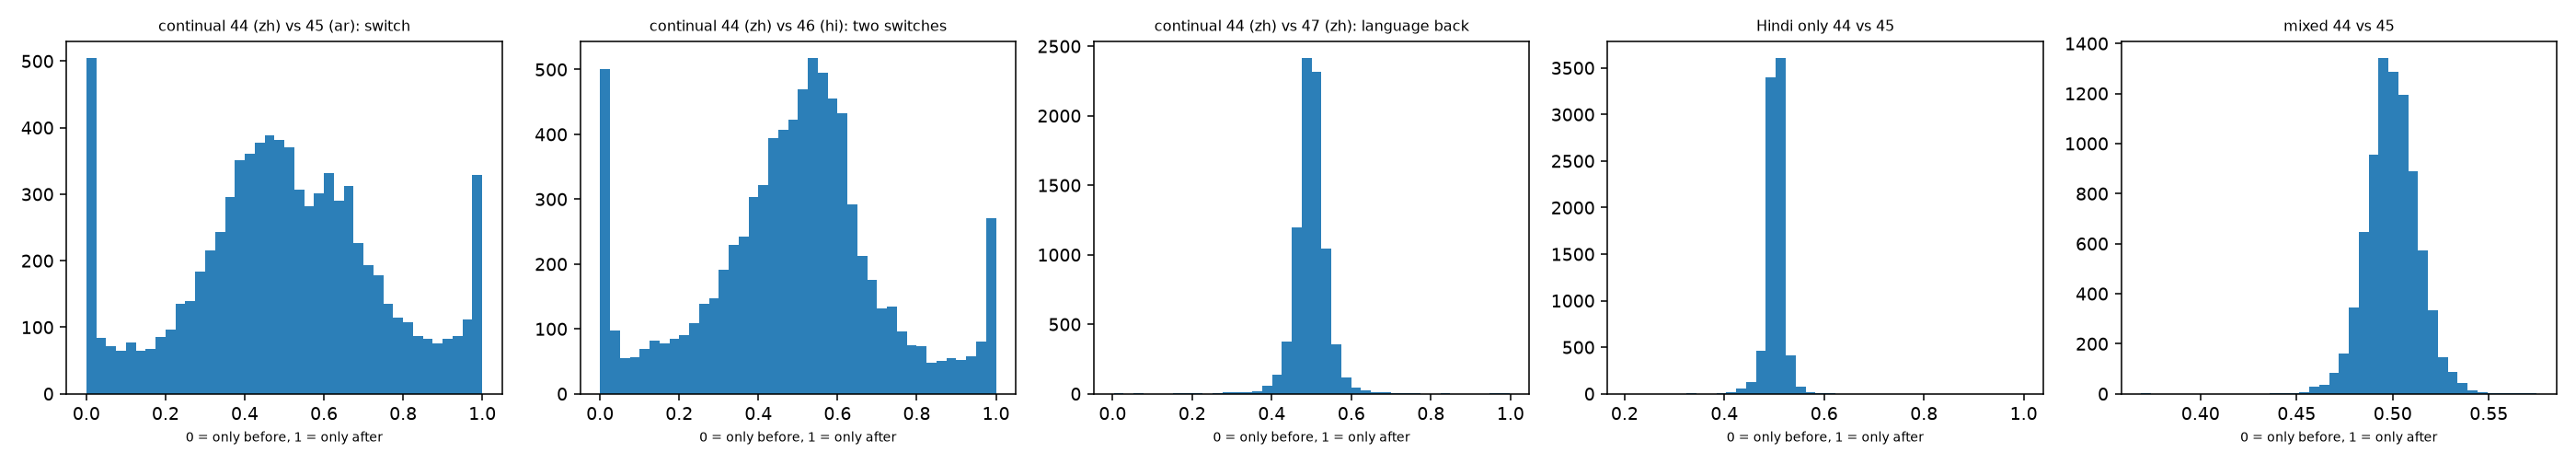

In [4]:
print(open("analysis/v6/v6c_B/report.txt").read())
for f in ["analysis/v6/v6c_B/crosscoder.png"]:
    if os.path.exists(f):
        display(Image(f))